# Initial exploration

The same CFPB file as the complaint-escalation project, complaints received between 1 Jan 2015 and 24 Apr 2017. This time the question is what's in the complaint text.

In [1]:
import pandas as pd

pd.set_option("display.max_colwidth", 200)

In [2]:
df = pd.read_parquet("../data/complaints.parquet")
df.shape

(432952, 18)

## Which complaints have a narrative

In [3]:
has_text = df["Consumer complaint narrative"].notna()
has_text.sum(), has_text.mean()

(np.int64(164437), np.float64(0.37980422772039396))

In [4]:
df.loc[has_text, "Date received"].min()

Timestamp('2015-03-19 00:00:00')

In [5]:
pd.crosstab(df["Consumer consent provided?"], has_text)

Consumer complaint narrative,False,True
Consumer consent provided?,,
Consent not provided,125547,0
Consent provided,28,164437
Consent withdrawn,10,0
N/A,134442,0
Other,8450,0


In [6]:
pd.crosstab(df["Submitted via"], has_text)

Consumer complaint narrative,False,True
Submitted via,,
Email,16,0
Fax,5576,0
Phone,25946,0
Postal mail,24809,0
Referral,52753,0
Web,159415,164437


In [7]:
web = df[(df["Submitted via"] == "Web") & (df["Date received"] >= "2015-03-19")]
len(web), web["Consumer complaint narrative"].notna().mean()

(298510, np.float64(0.5508592676962246))

In [8]:
has_text.groupby(df["Date received"].dt.to_period("M")).mean().round(2)

Date received
2015-01    0.00
2015-02    0.00
2015-03    0.16
2015-04    0.39
2015-05    0.41
2015-06    0.41
2015-07    0.42
2015-08    0.41
2015-09    0.40
2015-10    0.42
2015-11    0.40
2015-12    0.40
2016-01    0.41
2016-02    0.39
2016-03    0.39
2016-04    0.40
2016-05    0.40
2016-06    0.39
2016-07    0.41
2016-08    0.40
2016-09    0.43
2016-10    0.42
2016-11    0.40
2016-12    0.43
2017-01    0.45
2017-02    0.42
2017-03    0.43
2017-04    0.44
Freq: M, Name: Consumer complaint narrative, dtype: float64

In [9]:
has_text.groupby(df["Product"], observed=True).agg(["sum", "mean"]).sort_values("sum", ascending=False).head(10).round(2)

,sum,mean
Product,,
Debt collection,40387,0.42
Mortgage,32858,0.34
Credit reporting,31587,0.33
Credit card,18837,0.41
Bank account or service,14884,0.32
Student loan,11171,0.50
Consumer Loan,9461,0.45
Payday loan,1746,0.48
Money transfers,1497,0.41


## Dispute flag

In [10]:
labelled = df[df["Consumer disputed?"] != "N/A"]
disputed = labelled["Consumer disputed?"] == "Yes"
disputed.groupby(labelled["Consumer complaint narrative"].notna()).agg(["size", "mean"])

,size,mean
Consumer complaint narrative,,
False,268157,0.161346
True,164003,0.218331


Complaints with a narrative are disputed more often. They're all web complaints, so compare inside web only.

In [11]:
web = labelled[(labelled["Submitted via"] == "Web") & (labelled["Date received"] >= "2015-03-19")]
(web["Consumer disputed?"] == "Yes").groupby(web["Consumer consent provided?"], observed=True).agg(["size", "mean"])

,size,mean
Consumer consent provided?,,
Consent not provided,125300,0.175172
Consent provided,164031,0.218318
Consent withdrawn,8,0.125000
Other,8447,0.204925


## What the text looks like

In [12]:
narrative = df.loc[has_text, "Consumer complaint narrative"]
for text in narrative.head(3):
    print(text)
    print()

I am a customer of Rushcard. On XXXX/XXXX/15 my employer direct deposited {$400.00}, however, on XXXX/XXXX/15 there was a deposit reversal done by this company not my employer. I simply want my money back. It is mid XXXX and I still cant get through to customer service and I have no idea how to get information on my funds.

This individual contacted my father, who is in another state, and disclosed that he was collecting a debt to him. I have not lived with my father in over XXXX years. They made ZERO attempt to contact me before calling my XXXX father.

i entered disputes with all XXXX bureaus. i do not know what steps to take next they told me to contact creditors for them reporting incorrect information. i sent them my police report and ftc statement.



In [13]:
words = narrative.str.split().str.len()
words.describe().round(0)

count    164437.0
mean        191.0
std         167.0
min           1.0
25%          71.0
50%         136.0
75%         255.0
max        2213.0
Name: Consumer complaint narrative, dtype: float64

<Axes: >

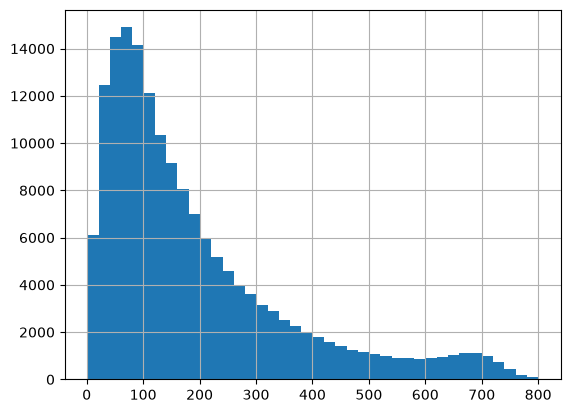

In [14]:
words.clip(upper=800).hist(bins=40)

In [15]:
narrative.str.len().quantile([0.5, 0.9, 0.99, 1])

0.50      737.0
0.90     2379.0
0.99     3876.0
1.00    11258.0
Name: Consumer complaint narrative, dtype: float64

In [16]:
(words < 10).sum(), (words < 20).sum()

(np.int64(1183), np.int64(5552))

In [17]:
narrative[words < 5].head(10)

1760                    this is not mine
3290            Victim of Identity Theft
6522                Account was verified
15827                 Debt has been paid
19863              could not get reports
24249                  I paid this bill.
26211                 Name is incorrect.
27893               Amount paid in full.
28943             My identity got stolen
30102    incorrect information reporting
Name: Consumer complaint narrative, dtype: str

## Redactions

In [18]:
narrative.str.contains("XXXX").mean(), narrative.str.count("XXXX").mean()

(np.float64(0.8256840005594848), np.float64(8.998564799892968))

In [19]:
narrative.str.contains("{$", regex=False).mean()

np.float64(0.3067496974525198)

In [20]:
narrative.str.isupper().mean()

np.float64(0.012904638250515394)

## Repeated texts

In [21]:
counts = narrative.value_counts()
(counts > 1).sum(), narrative.duplicated().sum()

(np.int64(1865), np.int64(3103))

In [22]:
counts.head(5)

Consumer complaint narrative
I am filing this complaint because Experian has ignored my request to provide me with the documents that their company has on file that was used to verify the accounts I disputed. Being that they have gone past the 30 day mark and can not verify these accounts, under Section 611 ( 5 ) ( A ) of the FCRA - they are required to " ... promptly delete all information which can not be verified '' that I have disputed. Please resolve this manner as soon as possible. Thank you.                                                                       103
I am filing this complaint because TransUnion has ignored my request to provide me with the documents that their company has on file that was used to verify the accounts I disputed. Being that they have gone past the 30 day mark and can not verify these accounts, under Section 611 ( 5 ) ( A ) of the FCRA - they are required to " ... promptly delete all information which can not be verified '' that I have disputed. Plea

In [23]:
top = df[df["Consumer complaint narrative"] == counts.index[0]]
top[["Company", "Consumer disputed?"]].astype(str).value_counts()

Company                              Consumer disputed?
Experian Information Solutions Inc.  No                    103
Name: count, dtype: int64

In [24]:
with_text = labelled[labelled["Consumer complaint narrative"].notna()]
repeated = with_text["Consumer complaint narrative"].duplicated(keep=False)
(with_text["Consumer disputed?"] == "Yes").groupby(repeated).agg(["size", "mean"])

,size,mean
Consumer complaint narrative,,
False,159050,0.220107
True,4953,0.161316


## Length and disputes

In [25]:
length = pd.cut(words[with_text.index], [0, 25, 50, 100, 200, 400, 2500])
(with_text["Consumer disputed?"] == "Yes").groupby(length).agg(["size", "mean"]).round(3)

,size,mean
Consumer complaint narrative,,
"(0, 25]",8969,0.147
"(25, 50]",16536,0.170
"(50, 100]",36493,0.192
"(100, 200]",46579,0.217
"(200, 400]",36006,0.246
"(400, 2500]",19420,0.295


Longer narratives are disputed more often, 14.7% up to 25 words and 29.5% over 400.